# Building-level imagery coverage with Imageable

This notebook prepares the building footprints that are fully within the study area. Later cells can use Imageable to examine imagery coverage for those buildings.

In [11]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt

In [12]:
PROJECT_ROOT = Path(
    "/Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis"
)
STUDY_AREA_PATH = PROJECT_ROOT / "data" / "spatial" / "bounding_box.geojson"
BOSTON_FOOTPRINTS_PATH = Path(
    "/Users/legariapena.j/Library/CloudStorage/GoogleDrive-legariapena.j@husky.neu.edu/"
    "Shared drives/Cool and Carbon Free Africa/Building Image Datasets/data/boston/"
    "footprints/boston_buildings.geojson"
)
OUTPUT_DIR = (
    PROJECT_ROOT
    / "data"
    / "2026_07_21_imagery_and_weather_station_data_exploration"
)
OUTPUT_FOOTPRINTS_PATH = OUTPUT_DIR / "boston_buildings_study_area.geojson"

In [13]:
study_area = gpd.read_file(STUDY_AREA_PATH)

if study_area.crs is None:
    raise ValueError("The study-area file does not define a CRS.")

# The Boston footprint file uses longitude/latitude coordinates.
study_area_wgs84 = study_area.to_crs("EPSG:4326")
study_geometry = study_area_wgs84.geometry.union_all()

print("Original study-area CRS:", study_area.crs)
print("Filtering CRS:", study_area_wgs84.crs)
print("Study-area bounds:", study_area_wgs84.total_bounds)

Original study-area CRS: EPSG:26986
Filtering CRS: EPSG:4326
Study-area bounds: [-71.10247018  42.33224997 -71.07925945  42.34584363]


In [14]:
# Use a bounding-box read first so GeoPandas does not load every Boston building.
footprint_candidates = gpd.read_file(
    BOSTON_FOOTPRINTS_PATH,
    bbox=tuple(study_area_wgs84.total_bounds),
)

if footprint_candidates.crs is None:
    raise ValueError("The Boston footprint file does not define a CRS.")

# Align CRS before applying the exact spatial predicate.
study_geometry_in_footprint_crs = (
    study_area_wgs84
    .to_crs(footprint_candidates.crs)
    .geometry
    .union_all()
)
building_footprints = footprint_candidates.loc[
    footprint_candidates.geometry.within(study_geometry_in_footprint_crs)
].copy()
building_footprints = building_footprints.reset_index(drop=True)

print(f"Bounding-box candidates: {len(footprint_candidates):,}")
print(f"Buildings fully within the study area: {len(building_footprints):,}")
building_footprints.head()

Bounding-box candidates: 2,637
Buildings fully within the study area: 2,456


,OBJECTID,PART_USE,PART_BRA_U,GRND_ELEV_2010,ROOF_ELEV_2010,BLDG_HGT_2010,IEL_TYPE,Land_Use,BRA_Land_Use,Added,Shape_Length,Shape_Area,shape_wkt,geometry
0,422,C,C,12.0,25.615,13.615,BLDG,C,C,NaN,0.000836,2.606018e-08,NaN,"POLYGON ((-71.09827 42.34483, -71.09841 42.344..."
1,423,C,C,8.0,49.410,41.410,BLDG,C,C,NaN,0.001201,7.536398e-08,NaN,"POLYGON ((-71.09979 42.34566, -71.09993 42.345..."
2,424,A,A,8.0,56.990,48.990,BLDG,A,A,NaN,0.001082,4.282650e-08,NaN,"POLYGON ((-71.08957 42.34476, -71.08957 42.344..."
3,425,E,XG,8.0,32.360,24.360,BLDG,XG,XG,NaN,0.001415,9.175381e-08,NaN,"POLYGON ((-71.0912 42.34432, -71.09126 42.3443..."
4,426,E,XG,6.0,22.680,16.680,BLDG,XG,XG,NaN,0.000571,1.952804e-08,MULTIPOLYGON ZM (((-71.091375939999978 42.3442...,"POLYGON ((-71.09138 42.34423, -71.09149 42.344..."


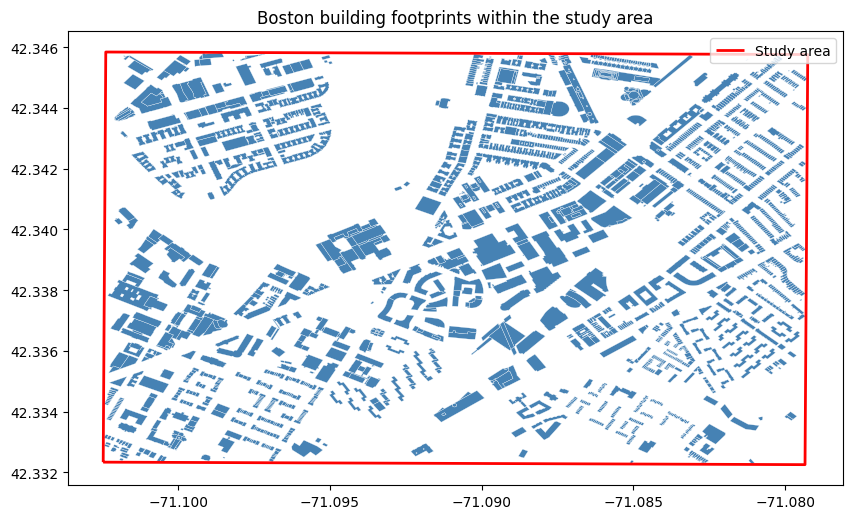

In [15]:
fig, ax = plt.subplots(figsize=(10, 10))
study_area_wgs84.boundary.plot(ax=ax, color="red", linewidth=2, label="Study area")
building_footprints.plot(ax=ax, color="steelblue", edgecolor="white", linewidth=0.2)
ax.set_title("Boston building footprints within the study area")
ax.set_aspect("equal")
ax.legend()
plt.show()

In [16]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
building_footprints.to_file(OUTPUT_FOOTPRINTS_PATH, driver="GeoJSON")
print(f"Saved {len(building_footprints):,} footprints to {OUTPUT_FOOTPRINTS_PATH}")

Saved 2,456 footprints to /Users/legariapena.j/Documents/open-sensing-analysis/open-sensing-analysis/data/2026_07_21_imagery_and_weather_station_data_exploration/boston_buildings_study_area.geojson


In [ ]:
import geopandas as gpd
import numpy as np
from shapely.geometry import Point
from tqdm.auto import tqdm

from imageable._images.camera.building_observation import (
    ObservationPointEstimator,
)

STREET_NETWORK_PATH = (
    PROJECT_ROOT
    / "data"
    / "2026_07_21_imagery_and_weather_station_data_exploration"
    / "street_network.geojson"
)

street_network = gpd.read_file(STREET_NETWORK_PATH)

results = []

for footprint in tqdm(building_footprints.geometry):
    estimator = ObservationPointEstimator(
        polygon=footprint,
        street_network=street_network,
    )

    observation_point, facade_midpoint, heading, distance_m = (
        estimator.get_observation_point()
    )

    results.append({
        "observation_point": (
            Point(observation_point)
            if observation_point is not None
            else None
        ),
        "facade_midpoint": (
            Point(facade_midpoint)
            if facade_midpoint is not None
            else None
        ),
        "heading": heading,
        "distance_m": (
            distance_m if np.isfinite(distance_m) else None
        ),
    })

/Users/legariapena.j/Documents/imageable-2026/imageable/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/legariapena.j/Documents/imageable-2026/imageable/.venv/lib/python3.13/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
 99%|█████████▉| 2429/2456 [03:41<00:02, 10.95it/s]


AttributeError: 'MultiPolygon' object has no attribute 'exterior'

In [21]:
from shapely import Polygon, MultiPolygon

def imageable_polygon(geometry):
    """Convert a Polygon/MultiPolygon into one Polygon for Imageable."""
    if isinstance(geometry, Polygon):
        return geometry

    if isinstance(geometry, MultiPolygon):
        return max(
            geometry.geoms,
            key=lambda polygon: polygon.area,
        )

    return None

start_index = len(results)

for footprint in tqdm(
    building_footprints.geometry.iloc[start_index:],
    initial=start_index,
    total=len(building_footprints),
):
    footprint = imageable_polygon(footprint)

    if footprint is None or footprint.is_empty:
        results.append({
            "observation_point": None,
            "facade_midpoint": None,
            "heading": None,
            "distance_m": None,
        })
        continue

    estimator = ObservationPointEstimator(
        polygon=footprint,
        street_network=street_network,
    )

    observation_point, facade_midpoint, heading, distance_m = (
        estimator.get_observation_point()
    )

    results.append({
        "observation_point": (
            Point(observation_point)
            if observation_point is not None
            else None
        ),
        "facade_midpoint": (
            Point(facade_midpoint)
            if facade_midpoint is not None
            else None
        ),
        "heading": heading,
        "distance_m": (
            distance_m
            if np.isfinite(distance_m)
            else None
        ),
    })


if len(results) != len(building_footprints):
    raise ValueError("The number of results does not match the number of buildings.")

building_footprints["observation_point"] = [
    result["observation_point"] for result in results
]

building_footprints["facade_midpoint"] = [
    result["facade_midpoint"] for result in results
]

building_footprints["heading"] = [
    result["heading"] for result in results
]

building_footprints["observation_distance_m"] = [
    result["distance_m"] for result in results
]


    

100%|██████████| 2456/2456 [00:00<?, ?it/s]


In [22]:
import requests
from tqdm.auto import tqdm

def fetch_streetview_metadata(api_key, observation_point):
    """observation_point must be a Shapely Point in EPSG:4326."""
    response = requests.get(
        "https://maps.googleapis.com/maps/api/streetview/metadata",
        params={
            "location": (
                f"{observation_point.y},{observation_point.x}"
            ),
            "key": api_key,
        },
        timeout=15,
    )
    response.raise_for_status()
    return response.json()

metadata_results = []

GOOGLE_MAPS_API_KEY = ""
for observation_point in tqdm(
    building_footprints["observation_point"]
):
    if observation_point is None:
        metadata_results.append({
            "status": "NO_OBSERVATION_POINT"
        })
        continue

    metadata_results.append(
        fetch_streetview_metadata(
            GOOGLE_MAPS_API_KEY,
            observation_point,
        )
    )



100%|██████████| 2456/2456 [14:06<00:00,  2.90it/s]


In [23]:
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

if len(metadata_results) != len(building_footprints):
    raise ValueError(
        "metadata_results must contain one result per building."
    )

# Add availability information to each building
building_footprints["image_available"] = [
    metadata is not None and metadata.get("status") == "OK"
    for metadata in metadata_results
]

building_footprints["imagery_status"] = [
    metadata.get("status", "UNKNOWN")
    if metadata is not None
    else "NO_METADATA"
    for metadata in metadata_results
]

In [24]:
map_crs = "EPSG:3857"

buildings_web = building_footprints.to_crs(map_crs)
streets_web = street_network.to_crs(map_crs)

# GeoPandas ignores None geometries when plotting
observation_points = gpd.GeoDataFrame(
    building_footprints[
        ["image_available", "imagery_status"]
    ].copy(),
    geometry=building_footprints["observation_point"],
    crs=building_footprints.crs,  # Should be EPSG:4326
)

observation_points = observation_points.dropna(
    subset=["geometry"]
).to_crs(map_crs)


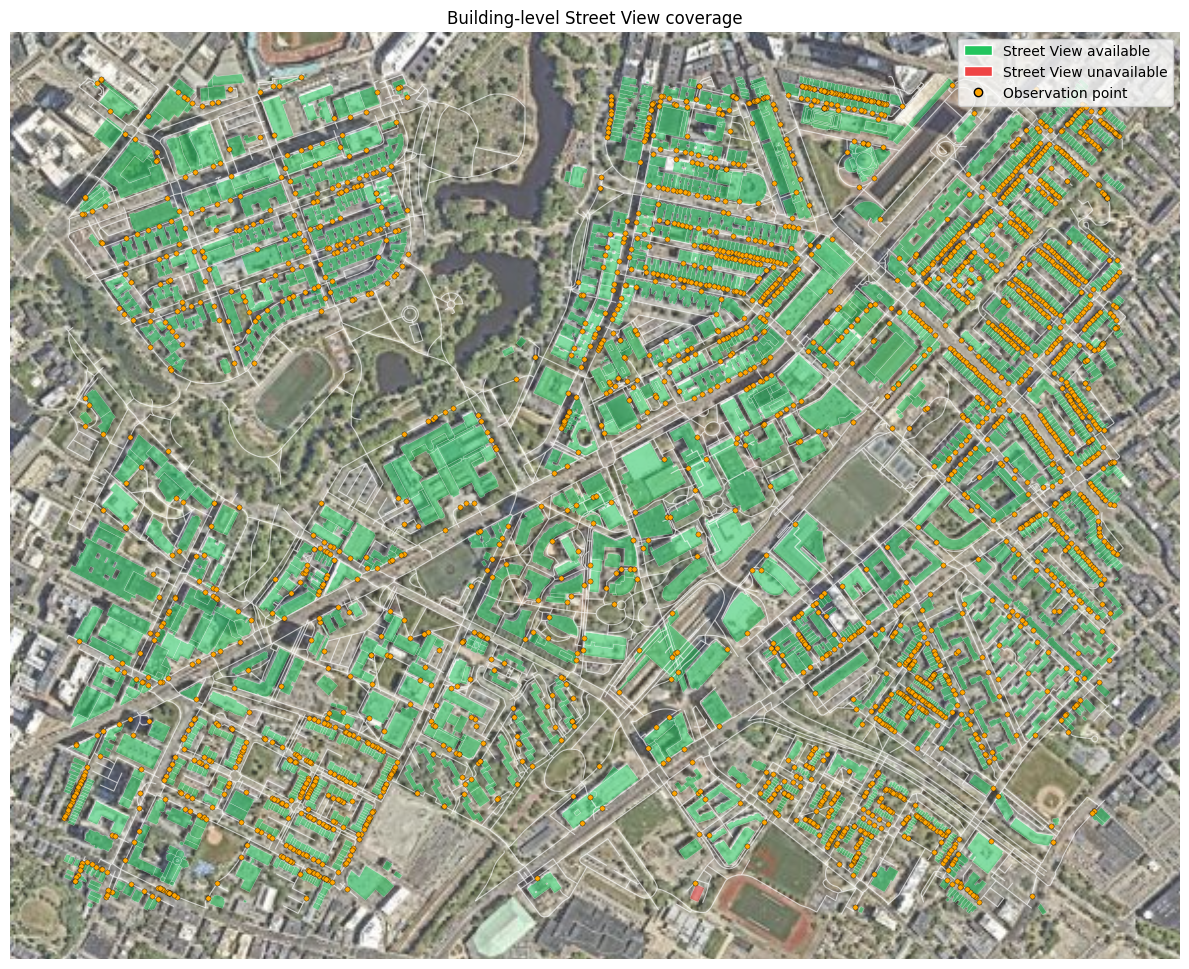

In [31]:
fig, ax = plt.subplots(figsize=(12, 12))

availability_colors = {
    True: "#22c55e",   # green
    False: "#ef4444",  # red
}

# Building footprints
buildings_web.plot(
    ax=ax,
    color=buildings_web["image_available"].map(
        availability_colors
    ),
    edgecolor="white",
    linewidth=0.25,
    alpha=0.55,
    zorder=1,
)

# Street network
streets_web.plot(
    ax=ax,
    linewidth=0.8,
    color="white",
    alpha=0.65,
    zorder=2,
)

# Observation points
observation_points.plot(
    ax=ax,
    color="orange",
    markersize=14,
    edgecolor="black",
    linewidth=0.25,
    zorder=3,
)

# ArcGIS aerial imagery
ctx.add_basemap(
    ax,
    source=ctx.providers.Esri.WorldImagery,
    crs=map_crs,
    attribution=False,
    alpha=0.8,
    zorder=0,
)

legend_elements = [
    Patch(
        facecolor="#22c55e",
        edgecolor="white",
        label="Street View available",
    ),
    Patch(
        facecolor="#ef4444",
        edgecolor="white",
        label="Street View unavailable",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor="orange",
        markeredgecolor="black",
        markersize=6,
        label="Observation point",
    ),
]

ax.legend(handles=legend_elements, loc="upper right")
ax.set_title("Building-level Street View coverage")
ax.set_axis_off()
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

In [35]:
images_available = sum(building_footprints["image_available"])/len(building_footprints["image_available"])
print(f"Fraction of images available {images_available}")

Fraction of images available 0.9995928338762216
